In [ ]:
# Superstore Analysis

In [ ]:
# Data Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
# 1. Load the dataset
df = pd.read_csv('Superstore_Inconsistent_Data csv.csv')
print(f"Original shape: {df.shape}")

Original shape: (10014, 21)


In [4]:
# 2. Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

In [5]:
# 3. Standardize text columns (strip whitespace, convert to Title case)
text_cols = ['Segment', 'Ship Mode', 'Category', 'Region', 'Country', 'Sub-Category', 'City', 'State']
for col in text_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.title()
        df_clean[col] = df_clean[col].replace(['Nan', 'None'], pd.NA)

In [6]:
# Correct minor category typos if any exist
df_clean['Category'] = df_clean['Category'].replace('Office Supply', 'Office Supplies')

In [7]:
# 4. Convert date columns to datetime format
df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'], errors='coerce')
df_clean['Ship Date'] = pd.to_datetime(df_clean['Ship Date'], errors='coerce')

In [8]:
# 5. Handle missing values
# Fill missing Discounts with the median value
df_clean['Discount'] = df_clean['Discount'].fillna(df_clean['Discount'].median())

In [9]:
# For categorical/geographical missing values, you can drop them or fill with 'Unknown'
df_clean['Ship Mode'] = df_clean['Ship Mode'].fillna('Unknown')
df_clean['City'] = df_clean['City'].fillna('Unknown')
df_clean['State'] = df_clean['State'].fillna('Unknown')

In [10]:
print(f"Cleaned shape: {df_clean.shape}")

Cleaned shape: (9995, 21)


In [ ]:
#Step 2: Exploratory Data Analysis (EDA) & Key Formulas

In [13]:
# 1. Overall Summary Statistics
total_sales = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
overall_margin = (total_profit / total_sales) * 100

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_margin:.2f}%")

Total Sales: $2,307,017.78
Total Profit: $289,086.16
Overall Profit Margin: 12.53%


In [14]:
# 2. Sales & Profit by Category
category_performance = df_clean.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean')
).reset_index()
category_performance['Profit_Margin_%'] = (category_performance['Total_Profit'] / category_performance['Total_Sales']) * 100
print("\nCategory Performance:\n", category_performance)


Category Performance:
           Category  Total_Sales  Total_Profit  Avg_Discount  Profit_Margin_%
0        Furniture  750146.0013    17941.8612      0.177648         2.391783
1  Office Supplies  719764.5720   123291.4288      0.160637        17.129411
2       Technology  837107.2100   147852.8743      0.133595        17.662358


In [15]:
# 3. Regional Performance
regional_performance = df_clean.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()
print("\nRegional Performance:\n", regional_performance)


Regional Performance:
     Region  Total_Sales  Total_Profit
0  Central  499720.0408    40206.5285
1     East  680144.6230    93186.1304
2    South  400495.1770    45729.6417
3     West  726657.9425   109963.8637


In [ ]:
#Step 3: Visualizations & Python Code

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\sudhi\AppData\Local\Temp\ipykernel_32776\3150205233.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_performance, x='Category', y='Total_Sales', ax=axes[0, 0], palette='Blues_d')
C:\Users\sudhi\AppData\Local\Temp\ipykernel_32776\3150205233.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_performance, x='Category', y='Total_Profit', ax=axes[0, 1], palette='Greens_d')
C:\Users\sudhi\AppData\Local\Temp\ipykernel_32776\3150205233.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=regional_perfor

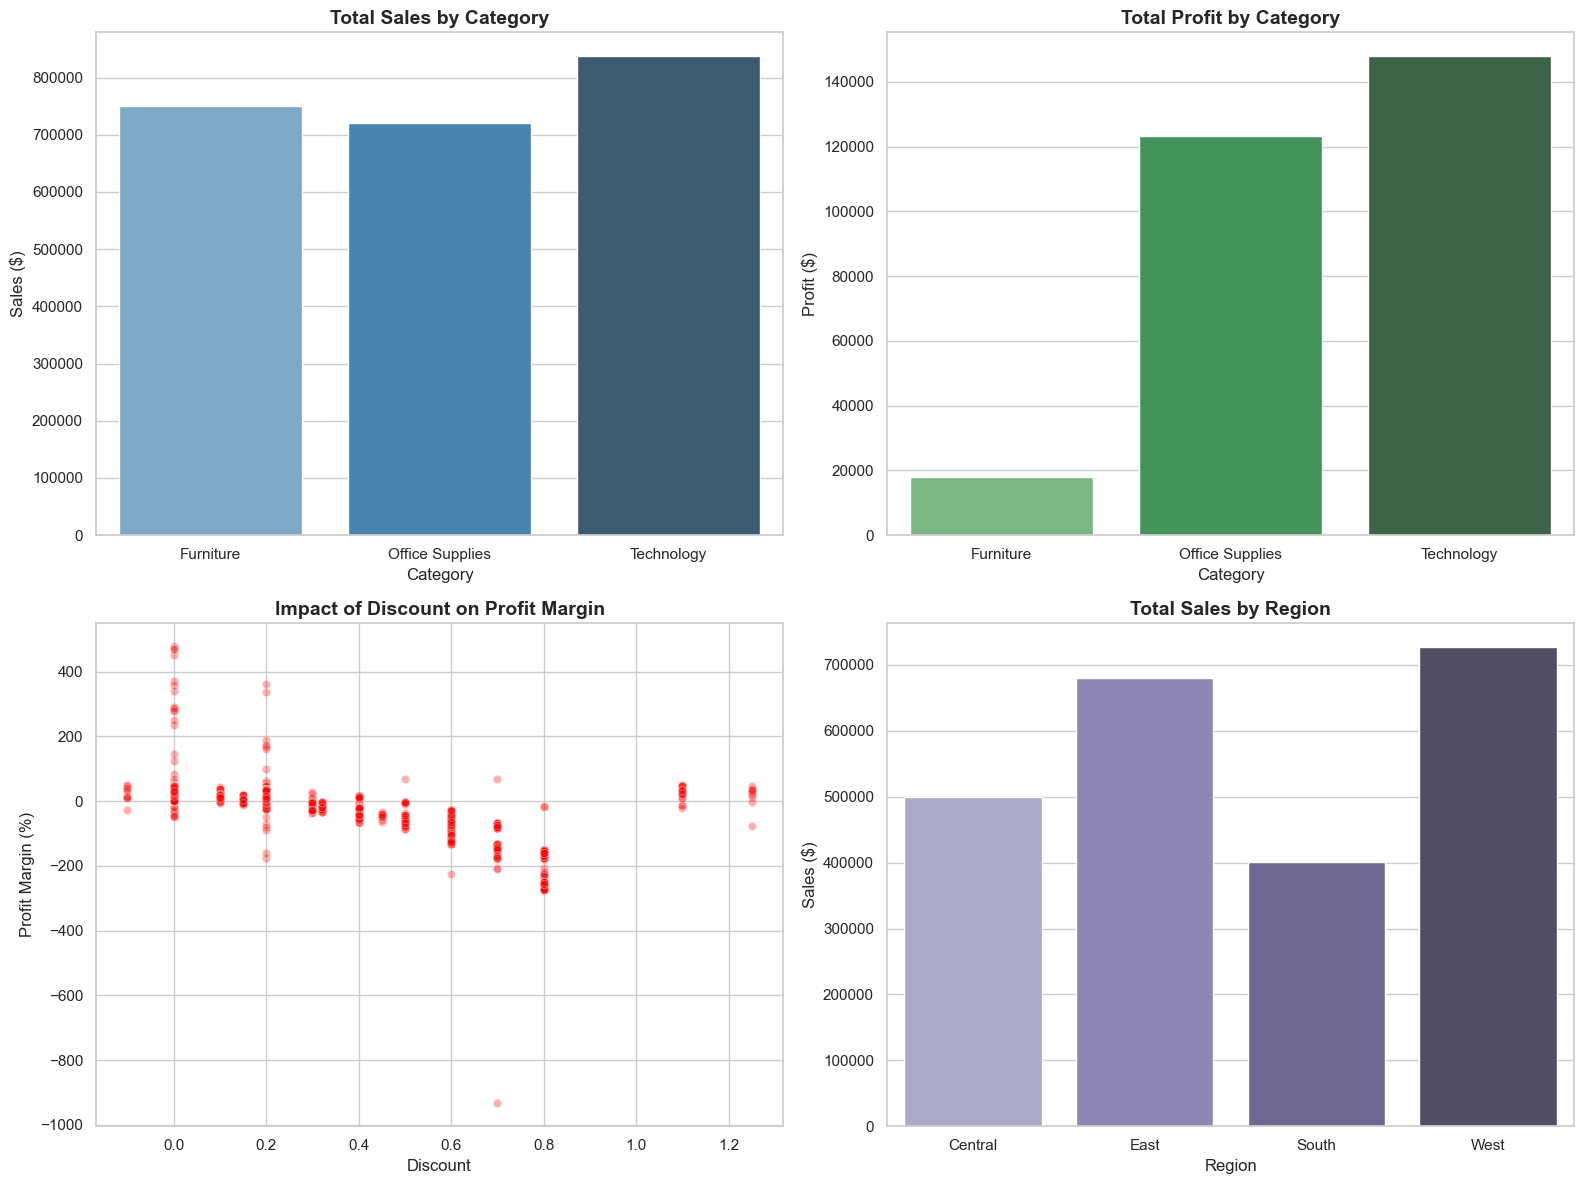

In [27]:

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Sales by Category (Bar Chart)
sns.barplot(data=category_performance, x='Category', y='Total_Sales', ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Total Sales by Category', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Sales ($)')

# 2. Profit by Category (Bar Chart)
sns.barplot(data=category_performance, x='Category', y='Total_Profit', ax=axes[0, 1], palette='Greens_d')
axes[0, 1].set_title('Total Profit by Category', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Profit ($)')

# 3. Discount vs Profit Margin (Scatter Plot / Line Trend)
sns.scatterplot(data=df_clean, x='Discount', y='Profit Margin', alpha=0.3, ax=axes[1, 0], color='red')
axes[1, 0].set_title('Impact of Discount on Profit Margin', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Profit Margin (%)')

# 4. Sales by Region (Bar Chart)
sns.barplot(data=regional_performance, x='Region', y='Total_Sales', ax=axes[1, 1], palette='Purples_d')
axes[1, 1].set_title('Total Sales by Region', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Sales ($)')

plt.tight_layout()
plt.savefig('superstore_analysis_dashboard.png', dpi=300)
plt.show()

In [ ]:
Box Plot (Detecting Outliers in Profit by Category)
Box plots are ideal for visualizing the distribution of numerical data and highlighting outliers (e.g., heavily discounted orders that caused extreme losses).

C:\Users\sudhi\AppData\Local\Temp\ipykernel_32776\3651023825.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


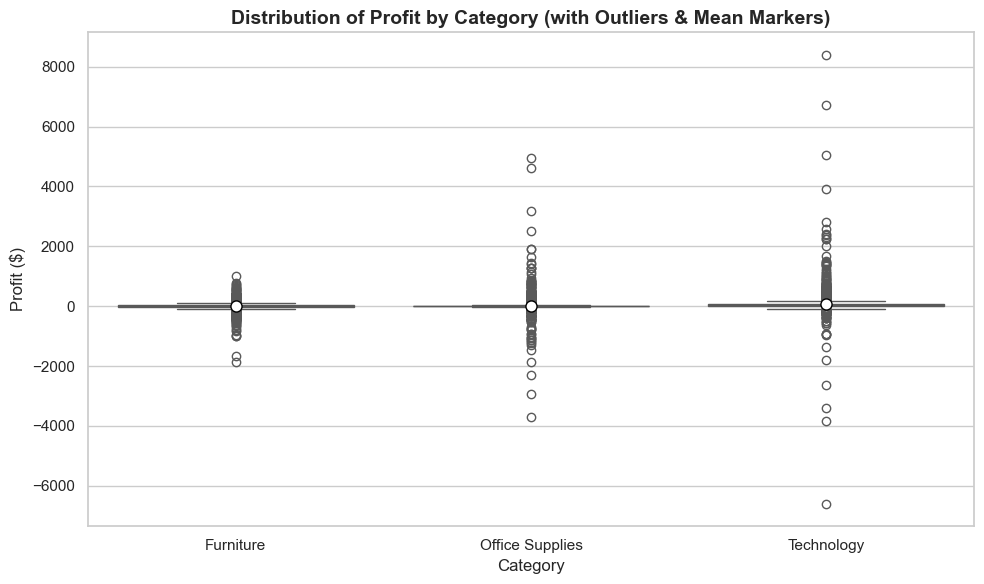

In [28]:
# Set up figure
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create Boxplot
sns.boxplot(
    data=df_clean, 
    x='Category', 
    y='Profit', 
    palette='Set2', 
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)

plt.title('Distribution of Profit by Category (with Outliers & Mean Markers)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)

plt.tight_layout()
plt.savefig('boxplot_profit_by_category.png', dpi=300)
plt.show()

In [ ]:
# Violin Plot (Profit Margin Distribution by Segment)
Violin plots combine box plots with kernel density estimation to show the full probability density of the data at different values. This is great for spotting multi-modal distributions.

C:\Users\sudhi\AppData\Local\Temp\ipykernel_32776\553836025.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\sudhi\AppData\Local\Temp\ipykernel_32776\553836025.py:8: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


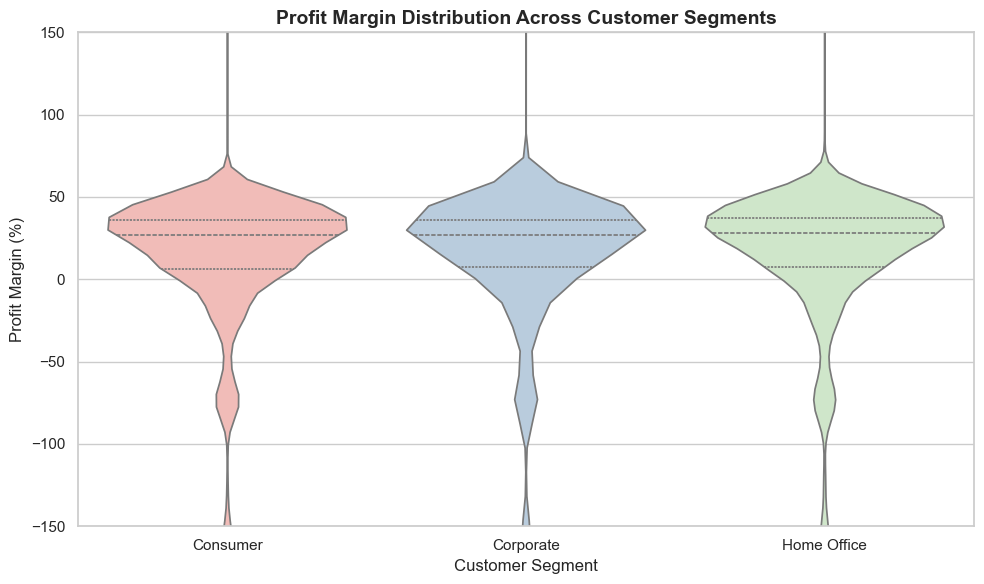

In [29]:
# Create Profit Margin column
df_clean['Profit Margin'] = (df_clean['Profit'] / df_clean['Sales']) * 100

# Set up figure
plt.figure(figsize=(10, 6))

# Create Violin Plot
sns.violinplot(
    data=df_clean, 
    x='Segment', 
    y='Profit Margin', 
    palette='Pastel1', 
    inner='quartile', 
    scale='width'
)

plt.title('Profit Margin Distribution Across Customer Segments', fontsize=14, fontweight='bold')
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Profit Margin (%)', fontsize=12)
plt.ylim(-150, 150) # Zooming in to focus on core distributions

plt.tight_layout()
plt.savefig('violinplot_profit_margin_by_segment.png', dpi=300)
plt.show()

In [ ]:
#Correlation Heatmap (Numerical Features)

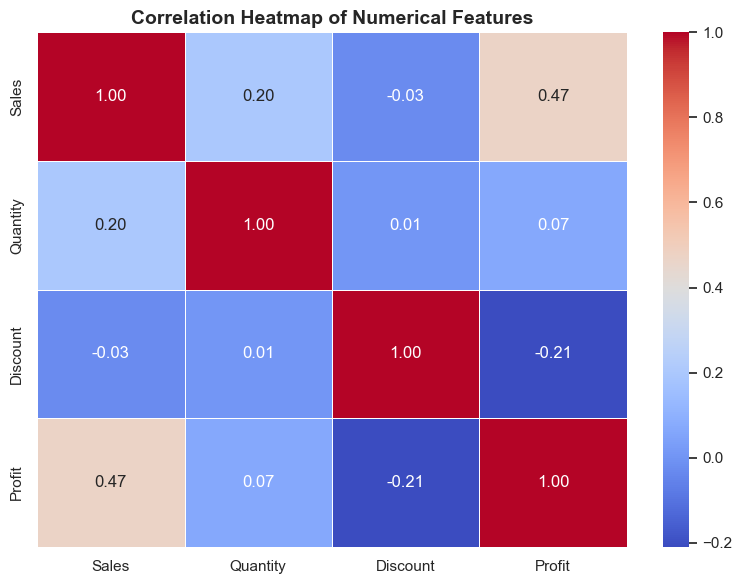

In [30]:
plt.figure(figsize=(8, 6))
numeric_cols = ['Sales', 'Quantity', 'Discount', 'Profit']
corr_matrix = df_clean[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

In [ ]:
#Monthly Sales Trend Line Chart

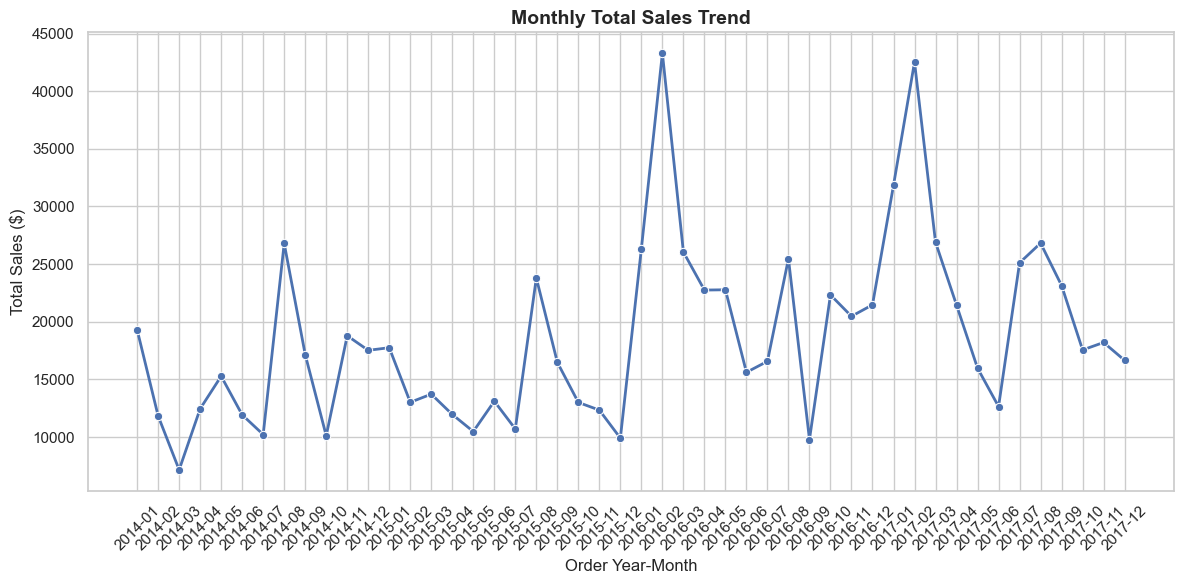

In [31]:
# Convert Order Date and extract year-month
df_clean['Order Date'] = pd.to_datetime(df_clean['Order Date'], errors='coerce')
df_clean['YearMonth'] = df_clean['Order Date'].dt.to_period('M')

monthly_sales = df_clean.groupby('YearMonth')['Sales'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_sales, x='YearMonth', y='Sales', marker='o', color='b', linewidth=2)

plt.title('Monthly Total Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Order Year-Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=300)
plt.show()